# Experimento 4 — Falta um efeito próprio do gênero?

Na execução anterior, os resíduos de drama foram predominantemente positivos.

**Hipótese:** acrescentar indicadores de gênero reduz o RMSE e as diferenças de resíduo médio entre gêneros.

Referência: duas médias + afinidade + afinidade². Candidato: os mesmos atributos + indicadores de comédia e drama (ação é a referência). Os indicadores mudam o nível da previsão, mantendo a curva de afinidade comum. Sem regularização ou busca.

**Protocolo:** 5 dobras × 5 repetições, semente 2026; mesmas partições para os modelos, apenas `train.csv`, previsões cortadas em [0, 5].

O RMSE considera as cinco previsões fora da dobra (OOF) de cada linha separadamente. Só os gráficos usam a média dessas previsões. As partições compartilham treino: desvios e vitórias são descritivos, não testes de significância. As hipóteses vieram da exploração destes dados; não são confirmação independente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold

N_SPLITS = 5
N_REPEATS = 5
SEED = 2026
CLIP = True
N_BINS = 8  # Somente visualização; não modifica os modelos.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
df = pd.read_csv(ROOT / 'data' / 'train.csv')
genres = ['action', 'comedy', 'drama']
assert set(df['genre'].unique()).issubset(genres)
required = ['user_avg_stars', 'movie_avg_stars', 'stars'] + ['share_' + g for g in genres]
assert not df[required].isna().any().any()
df['affinity'] = [row['share_' + row['genre']] for _, row in df.iterrows()]
assert df['affinity'].between(0, 1).all()
y = df['stars'].to_numpy(dtype=float)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
display(df[['genre', 'share_action', 'share_comedy', 'share_drama', 'affinity']].head())
print(f'{len(df)} linhas; {N_SPLITS} folds × {N_REPEATS} repetições; semente {SEED}; corte: {CLIP}')
df['affinity2'] = df['affinity'] ** 2

# Ação é a referência; categorias conhecidas não são aprendidas no conjunto.
df['genre_comedy'] = df['genre'].eq('comedy').astype(float)
df['genre_drama'] = df['genre'].eq('drama').astype(float)
BASE_FEATURES = ['user_avg_stars', 'movie_avg_stars', 'affinity', 'affinity2']
GENRE_FEATURES = BASE_FEATURES + ['genre_comedy', 'genre_drama']


,genre,share_action,share_comedy,share_drama,affinity
0,drama,0.315,0.501,0.184,0.184
1,action,0.180,0.151,0.669,0.180
2,action,0.701,0.258,0.041,0.701
3,action,0.700,0.204,0.096,0.700
4,action,0.621,0.257,0.122,0.621


4000 linhas; 5 folds × 5 repetições; semente 2026; corte: True


In [2]:
def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))

def predict_checked(model, X):
    # Equação explícita evita os avisos locais de matmul na regressão.
    prediction = (np.sum(X * model.coef_, axis=1) + model.intercept_
                  if isinstance(model, LinearRegression) else model.predict(X))
    assert np.isfinite(prediction).all()
    return np.clip(prediction, 0, 5) if CLIP else prediction


## 1. Ajustar os modelos nas mesmas partições

In [3]:
candidates = {'Sem gênero explícito': BASE_FEATURES, 'Com gênero explícito': GENRE_FEATURES}
folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(df))
predictions_by_repeat = {name: np.full((N_REPEATS, len(df)), np.nan) for name in candidates}
rows = []
for name, columns in candidates.items():
    X = df[columns].to_numpy(dtype=float)
    for partition, (train, valid) in enumerate(folds):
        model = LinearRegression().fit(X[train], y[train])
        pred = predict_checked(model, X[valid])
        predictions_by_repeat[name][partition // N_SPLITS, valid] = pred
        rows.append({'modelo': name, 'particao': partition + 1,
                     'RMSE validação': rmse(y[valid], pred),
                     'RMSE treino': rmse(y[train], predict_checked(model, X[train]))})
assert all(np.isfinite(values).all() for values in predictions_by_repeat.values())
oof = pd.DataFrame({name: values.mean(axis=0) for name, values in predictions_by_repeat.items()})
by_fold = pd.DataFrame(rows)
summary = by_fold.groupby('modelo', sort=False).agg(
    media_RMSE_particoes=('RMSE validação', 'mean'),
    desvio_particoes=('RMSE validação', 'std'),
    media_RMSE_treino=('RMSE treino', 'mean'))
summary.insert(0, 'RMSE OOF repetido', [rmse(y, predictions_by_repeat[name]) for name in summary.index])
display(summary.round(4))
paired = by_fold.pivot(index='particao', columns='modelo', values='RMSE validação')
reference, candidate = list(candidates)
paired['Candidato − referência'] = paired[candidate] - paired[reference]
display(paired.round(4))
print(f"Candidato melhora em {int((paired['Candidato − referência'] < 0).sum())}/{len(folds)} partições.")
per_repeat = pd.DataFrame({name: [rmse(y, pred) for pred in values]
                           for name, values in predictions_by_repeat.items()},
                          index=pd.Index(range(1, N_REPEATS + 1), name='repetição'))
per_repeat['Candidato − referência'] = per_repeat[candidate] - per_repeat[reference]
display(per_repeat.round(4))


,RMSE OOF repetido,media_RMSE_particoes,desvio_particoes,media_RMSE_treino
modelo,,,,
Sem gênero explícito,0.629,0.6288,0.0159,0.6277
Com gênero explícito,0.625,0.6249,0.0148,0.6234


modelo,Com gênero explícito,Sem gênero explícito,Candidato − referência
particao,,,
1,0.6256,0.6274,-0.0018
2,0.6216,0.6231,-0.0015
3,0.6146,0.6228,-0.0082
4,0.6397,0.6440,-0.0043
5,0.6215,0.6251,-0.0035
6,0.6424,0.6480,-0.0056
7,0.6267,0.6338,-0.0070
8,0.6135,0.6164,-0.0029
9,0.6204,0.6195,0.0009


Candidato melhora em 23/25 partições.


,Sem gênero explícito,Com gênero explícito,Candidato − referência
repetição,,,
1,0.6285,0.6247,-0.0038
2,0.6288,0.6249,-0.0039
3,0.6289,0.6251,-0.0038
4,0.6292,0.6250,-0.0043
5,0.6295,0.6255,-0.0040


## 2. O erro dos dramas diminuiu?

Compare RMSE global e por gênero. Resíduo médio mais próximo de zero não garante menor RMSE: a dispersão também importa.

,modelo,gênero,n,resíduo médio,RMSE OOF repetido
0,Sem gênero explícito,action,1462,0.0077,0.6186
1,Sem gênero explícito,comedy,1254,-0.0574,0.6424
2,Sem gênero explícito,drama,1284,0.1158,0.6275
3,Com gênero explícito,action,1462,0.0319,0.6212
4,Com gênero explícito,comedy,1254,0.0086,0.6382
5,Com gênero explícito,drama,1284,0.0241,0.6163


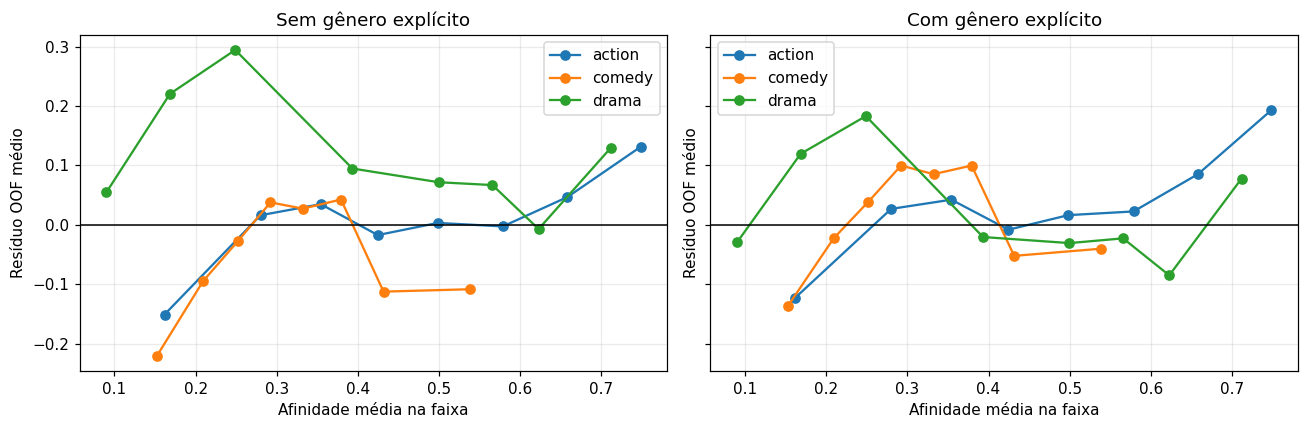

In [4]:
residuals = oof.apply(lambda prediction: y - prediction)
rows_genre = []
for name in candidates:
    for genre in genres:
        mask = df['genre'].eq(genre).to_numpy()
        rows_genre.append({'modelo': name, 'gênero': genre, 'n': int(mask.sum()),
                          'resíduo médio': residuals.loc[mask, name].mean(),
                          'RMSE OOF repetido': rmse(y[mask], predictions_by_repeat[name][:, mask])})
display(pd.DataFrame(rows_genre).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, name in zip(axes, candidates):
    for genre in genres:
        sub = df.loc[df['genre'].eq(genre), ['affinity']].copy()
        sub['residuo'] = residuals.loc[sub.index, name]
        table = sub.groupby(pd.qcut(sub['affinity'], N_BINS, duplicates='drop'), observed=True).agg(
            x=('affinity', 'mean'), residuo=('residuo', 'mean'))
        ax.plot(table['x'], table['residuo'], 'o-', label=genre)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(title=name, xlabel='Afinidade média na faixa', ylabel='Resíduo OOF médio')
    ax.legend()
plt.tight_layout()
plt.show()


## 3. Conclusão do grupo

- O ganho é relevante e consistente?
- O erro nos dramas diminuiu sem piorar muito os demais gêneros?
- Restam diferenças na forma das curvas?

**Questões para discussão após a execução registrada abaixo.** O próximo experimento mantém esses atributos para comparar famílias; registre se os indicadores não ajudarem.

## Registro reproduzível desta execução

Salvamos previsões OOF por repetição, erros por partição, configurações selecionadas, versões e identificadores dos dados e do código em `results/rodada_atual`. Esses arquivos não se misturam aos resultados históricos.

In [5]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.current_results import save_run
save_run(ROOT, '06_hipotese_genero', df, y, predictions_by_repeat, by_fold,
         N_SPLITS, N_REPEATS, SEED, CLIP, globals().get('selections'))

Resultados verificados e salvos em /Users/insider/Desktop/movie-rating-prediction-main/results/rodada_atual/06_hipotese_genero.json


## Leitura da execução de 15 de novembro de 2026

Os indicadores de gênero reduziram o RMSE de **0,628989 para 0,625036**: ganho de **0,003953**, com melhora em **23/25 partições** e nas cinco repetições. O resíduo médio dos dramas passou de **+0,1158 para +0,0241**; o das comédias, de **−0,0574 para +0,0086**. O ganho é modesto e os gráficos ainda mostram formas diferentes por gênero. Mantemos esta regressão como referência comum dos notebooks 07 e 08, que mudam o procedimento usando os mesmos atributos. Não inferimos causalidade.

Esta leitura se refere à execução salva nesta rodada. Desvios e contagens são descritivos, não testes independentes. Revisar os números e o texto se dados, código ou configuração mudarem. As questões do grupo permanecem abertas à discussão.